### Make a temporary space in /flash

In [1]:
import os, random, string

In [2]:
cwd = os.path.basename(os.getcwd())
tmpdir = os.path.join("/flash/ReiterU/tmp/", 'tomo_' + ''.join(random.choices(string.ascii_uppercase, k=12)))
print(tmpdir)
if not os.path.exists(tmpdir):
    os.makedirs(tmpdir)

/flash/ReiterU/tmp/tomo_MJOXOSPSUDZV


### Import stuff

In [3]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from nptdms import TdmsFile
import h5py
import cv2
import glob, os
from roifile import roiread

In [4]:
import sys
sys.path.append("/home/t/tomoyuki-mano1/projects/OL_calcium")
from calfuncs.io import read_sync_ttl
from calfuncs.lsn import get_ett_vectorized, plot_lsn_response, analyze_rf, plot_rf, fit_vector_field, plot_retinotopy, plot_vector_field

In [5]:
from matplotlib import font_manager
import matplotlib as mpl

font_manager.fontManager.addfont('/bucket/ReiterU/common/fonts/arial.ttf')
mpl.rcParams.update({
    'font.size': 7,
    'font.family': 'sans-serif',
    'font.sans-serif': "Arial",
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'xtick.major.size': 2,
    'xtick.minor.size': 2,
    'xtick.minor.width': 0.5,
    'ytick.major.width': 0.5,
    'ytick.minor.width': 0.5,
    'ytick.major.size': 2,
    'ytick.minor.size': 2,
})

In [6]:
### PARAMETERS ####
UM_PER_PIXEL = 0.52
DEGREE_PER_PIXEL = 2.0

In [7]:
#### path to relevant files
rootdir = "/bucket/ReiterU/OLdev/experiments/20241212_squid_cal520"
recname = "rec7"
savedir = "/bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20241212_rec7/plots"

templatefile = os.path.join(rootdir, "2P", recname, "run1/mcorr_nonrigid/QC/QC_nonrigid/template.tif")
roifile = os.path.join(rootdir, "2P", recname, "ROI_yutaka_renamed.zip")
dfffile = os.path.join(rootdir, "2P", recname, "dff_ROI_yutaka/DFF.hdf5")
syncfile = os.path.join(rootdir, "sync", f"{recname}.tdms")
lsn_matrix_file = "/bucket/ReiterU/OLdev/experiments/visual_stim/20241021_LSN_matrix/LSN_2DEG.npy"

### Load relevant files

In [8]:
sync_ttl = read_sync_ttl(syncfile)
twop_ttl = sync_ttl["twop_ttl"]
twop_re = sync_ttl["twop_re"]
vis_re = sync_ttl["vis_re"]
print(twop_ttl.shape, twop_re.shape, vis_re.shape)

(2094000,) (31885,) (2106,)


In [9]:
with h5py.File(dfffile, "r") as hf:
    # Y = hf["dff"][:]
    Y = hf["F"][:]
print(Y.shape) # Y is sampled at 1 kHz

(188, 2094000)


In [10]:
lsn_mat = np.load(lsn_matrix_file)
# flip x
lsn_mat = lsn_mat[:, :, ::-1]

print(lsn_mat.shape)

(1240, 31, 55)


In [11]:
template = cv2.imread(templatefile, -1)

In [12]:
rois = roiread(roifile)
rois = sorted(rois, key=lambda x: x.name)  # sort the list
contours = [r.subpixel_coordinates.astype("int") for r in rois]
coms = np.array([r.subpixel_coordinates.mean(axis=0) for r in rois])

## ETA for locally sparse noise (LSN)

In [13]:
%%time
E = []
for nid in np.arange(Y.shape[0]):
# for nid in np.arange(10):
    ett = get_ett_vectorized(Y, vis_re[0:1240], lsn_mat, nid, 2000, 4000, DEGREE_PER_PIXEL, mode="both", pixel_coordinate="center_origin", subsampling=50)
    ett["neuron"] = nid
    ett = ett.reset_index().set_index(["neuron", "y", "x", "trial", "time"])
    E.append(ett)
E = pd.concat(E)

CPU times: user 4min 13s, sys: 30.2 s, total: 4min 44s
Wall time: 4min 45s


In [14]:
display(E)

v
neuron y     x     trial time           
0      -31.0 -55.0 0     -2000       NaN
                         -1950       NaN
                         -1900       NaN
                         -1850       NaN
                         -1800       NaN
...                                  ...
187     29.0  53.0 19     3750 -0.285379
                          3800 -0.279342
                          3850 -0.257699
                          3900 -0.251114
                          3950 -0.113637

[755308800 rows x 1 columns]

In [15]:
rf_result = []

for nid in range(Y.shape[0]):
# for nid in range(10):
    print(nid)
    # plot_lsn_response(E, nid, 0, 1000, vmin=-0.05, vmax=0.4, cmap_name="viridis")
    rf =  analyze_rf(E, nid, 0, 1000, DEGREE_PER_PIXEL, peak_thresh=3.0, blob_thresh=2.5, sigma=0.8)
    # plot_rf(E, nid, rf, 0, 1000)
    rf_result.append({
        "neuron": nid,
        "azimuth": rf["loc_screen"][1],
        "elevation": rf["loc_screen"][0],
        "size": rf["size"],
        "x": coms[nid, 0] * UM_PER_PIXEL,
        "y": coms[nid, 1] * UM_PER_PIXEL,
    })

R = pd.DataFrame(rf_result)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187


In [16]:
R = pd.DataFrame(rf_result)

In [17]:
R["test"] = True
cond1 = R["size"] == 0
cond2 = (R["azimuth"] < -32) | (R["azimuth"] > -15)
cond3 = (R["elevation"] < -12) | (R["elevation"] > 10)
bad_index = R.index[cond1 | cond2 | cond3].tolist()
R.loc[bad_index, "test"] = False

In [18]:
display(R)

,neuron,azimuth,elevation,size,x,y,test
0,0,0.000000,0.000000,0.0,73.449997,33.344997,False
1,1,-19.000000,3.500000,16.0,98.366669,8.935332,True
2,2,0.000000,0.000000,0.0,95.647499,14.113125,False
3,3,52.333333,-5.666667,12.0,101.701050,37.063683,False
4,4,0.000000,0.000000,0.0,102.899994,60.289997,False
...,...,...,...,...,...,...,...
183,183,-21.000000,6.428571,28.0,97.124435,150.720535,True
184,184,0.000000,0.000000,0.0,92.736420,128.778915,False
185,185,-17.666667,5.222222,36.0,71.348320,146.907196,True
186,186,-19.000000,6.000000,24.0,78.779999,132.694534,True


In [19]:
with pd.HDFStore(os.path.join(tmpdir, "result.hdf5"), mode='w') as store:
    store.put('E', E)
    store.put('R', R)

In [20]:
# with pd.HDFStore("/bucket/ReiterU/OLdev/experiments/20250317_squid_cal520/2P/rec6/dff_ROI_yutaka/plots/result.hdf5", mode='r') as store:
#     R = store["R"]
#     E = store["E"]

### Color cells by RF location

In [21]:
R_filtered = R[R["test"]].reset_index()

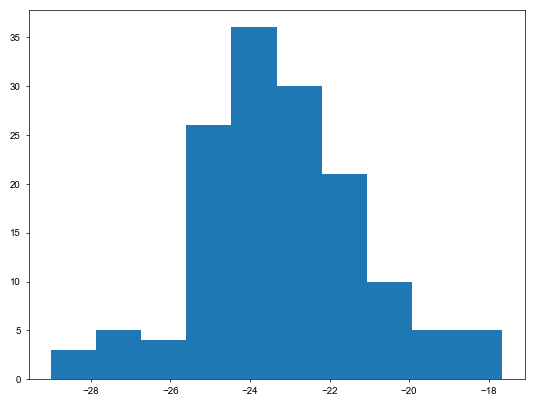

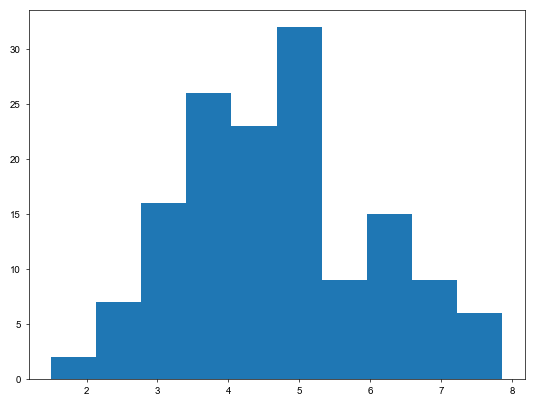

In [22]:
plt.hist(R_filtered["azimuth"])
plt.show()
plt.hist(R_filtered["elevation"])
plt.show()

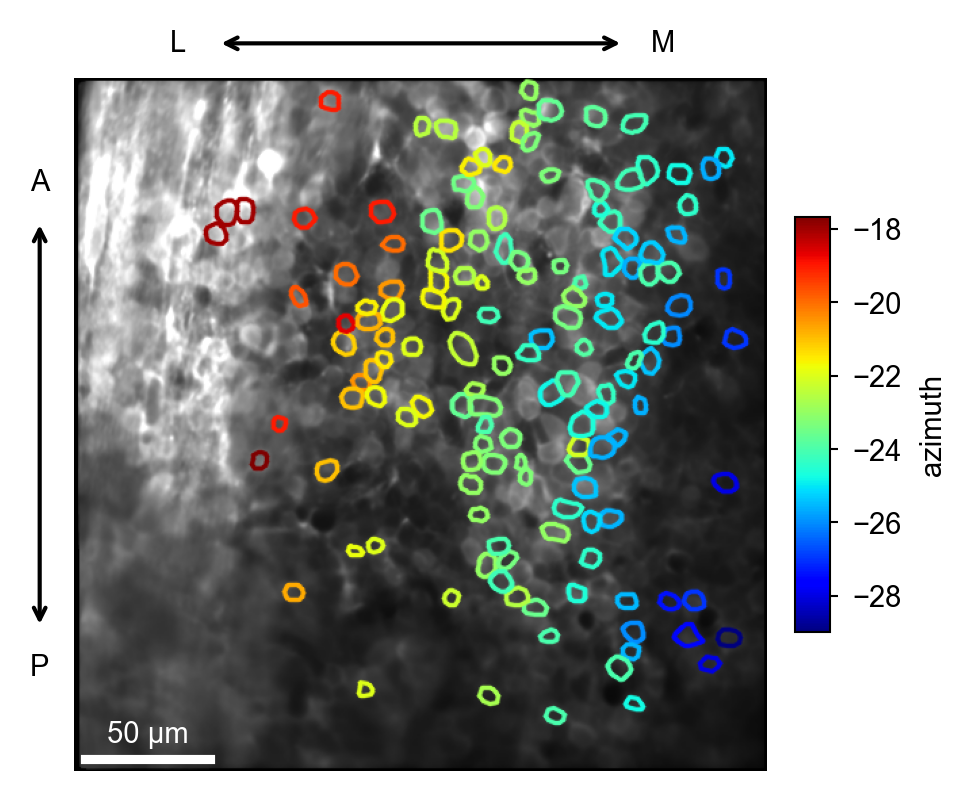

In [23]:
contours_filtered = [c for (i, c) in enumerate(contours) if i in R[R["test"]].index.to_list()]
plot_retinotopy(R_filtered, "azimuth", template, contours_filtered, show_cell_id=False, figsavename=os.path.join(tmpdir, "retinotopy_azimuth.pdf"))

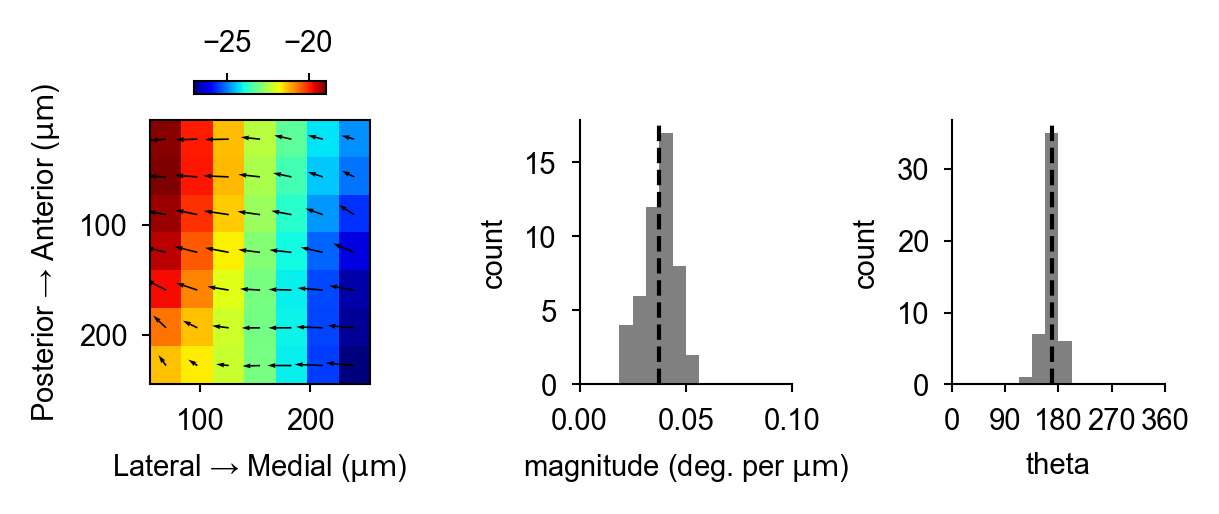

In [24]:
vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(R_filtered, "azimuth", n_bins=7)
_ = plot_vector_field(R_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y, figsavename=os.path.join(tmpdir, "retinotopy_vec_field_azimuth.pdf"))

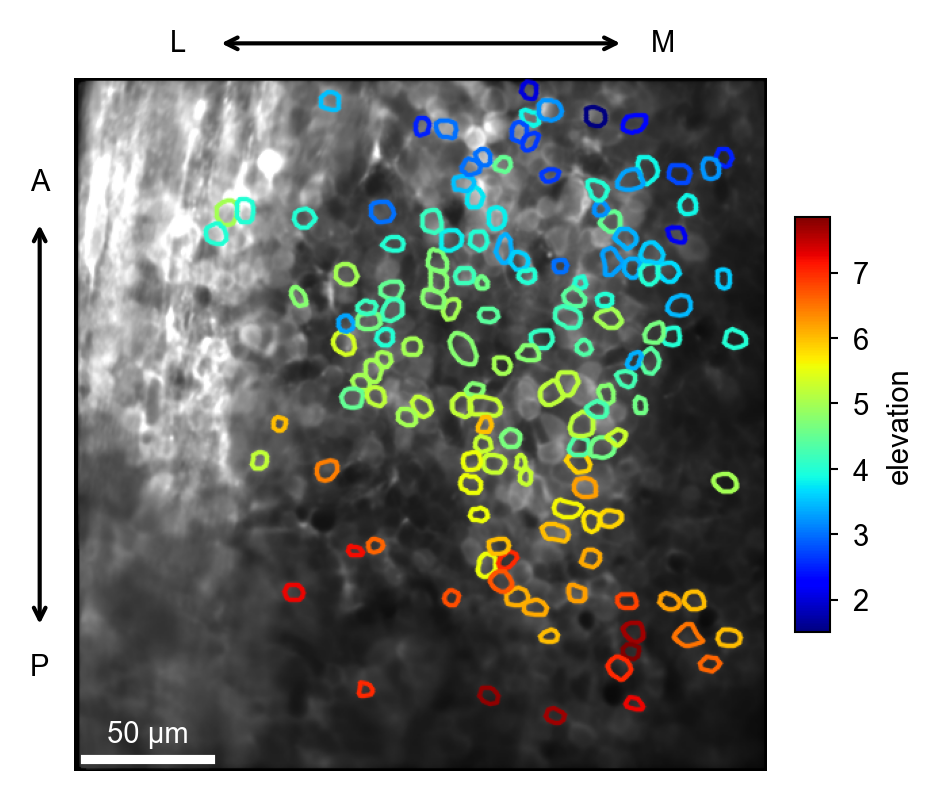

In [25]:
contours_filtered = [c for (i, c) in enumerate(contours) if i in R[R["test"]].index.to_list()]
plot_retinotopy(R_filtered, "elevation", template, contours_filtered, show_cell_id=False, figsavename=os.path.join(tmpdir, "retinotopy_elevation.pdf"))

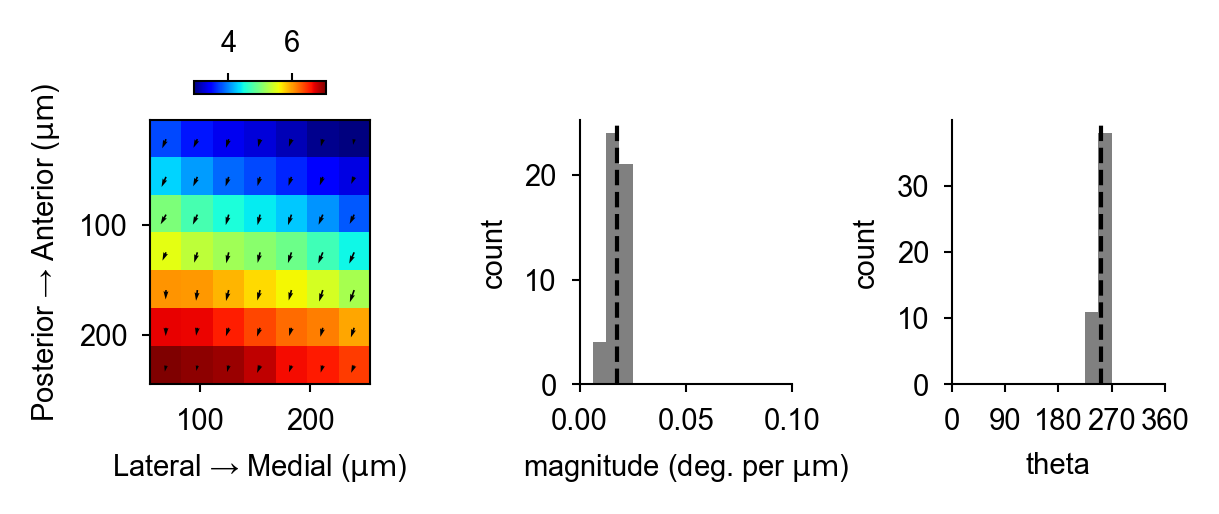

In [26]:
vfield, grad_x, grad_y, anchor_x, anchor_y = fit_vector_field(R_filtered, "elevation", n_bins=7)
_ = plot_vector_field(R_filtered, vfield, grad_x, grad_y, anchor_x, anchor_y, figsavename=os.path.join(tmpdir, "retinotopy_vec_field_elevation.pdf"))

### RF size distribution

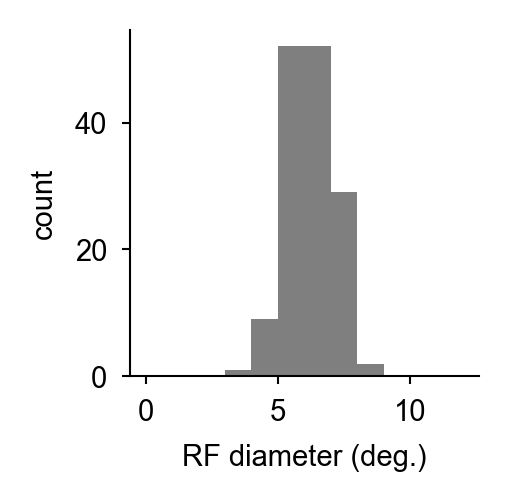

In [27]:
rf_sizes = R[R["test"]]["size"].to_numpy()
rf_diameter = 2 * np.sqrt(rf_sizes / np.pi)

count, bin_edges = np.histogram(rf_diameter, range=[0, 12], bins=12, density=False)
bin_centers = 0.5 * (bin_edges[1:] + bin_edges[:-1])

fig, ax = plt.subplots(figsize=(1.5,1.5), dpi=300)
ax.bar(bin_centers, count, width=bin_edges[1]-bin_edges[0], lw=0, alpha=0.5, color="k")
ax.set_xlabel("RF diameter (deg.)")
ax.set_ylabel("count")
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
plt.show()

### Copy data to bucket

In [29]:
print(f"mkdir -p {savedir}")
print(f"cp -r {tmpdir}/* {savedir}")

mkdir -p /bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20241212_rec7/plots
cp -r /flash/ReiterU/tmp/tomo_MJOXOSPSUDZV/* /bucket/ReiterU/OLdev/analysis/20250327_OGL_receptive_field/20241212_rec7/plots
